In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter, defaultdict
import csv
import hashlib
import json
import math
import random
import re
import sys
import os
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (
    SQLTransformer, RegexTokenizer, StopWordsRemover,
    CountVectorizer, CountVectorizerModel, IDF, Normalizer,
    NGram, HashingTF
)
from pyspark.ml.classification import LogisticRegression, NaiveBayes
from pyspark.ml.functions import vector_to_array

SEED = 42
ROOT = Path.cwd()
WORK = ROOT / "practice7_data"
OUT = ROOT / "practice7_results"
WORK.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SOURCE = ROOT / "sentiment_dataset.csv"
if not SOURCE.is_file():
    raise FileNotFoundError(f"Не найден файл: {SOURCE}")

spark = (SparkSession.builder.appName("TextAnalytics")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("WARN")
LABEL_NAMES = {0: "Нейтральный", 1: "Положительный",
               2: "Отрицательный"}

**1. Подготовить и исследовать корпус.** Составьте отчет о выбранных
произведениях. Укажите автора, work_group, число символов основного текста,
число полных фрагментов и split. Постройте распределения произведений и
фрагментов по авторам. Задайте правило учёта длинных произведений.
Например, отберите не более 50 обучающих фрагментов на группу по
воспроизводимому правилу. Другой вариант — использовать веса наблюдений. 

In [2]:
from zipfile import ZipFile
from pathlib import PurePosixPath

LIT_SOURCE = ROOT / "Literature.zip"
LIT_JSON = WORK / "literature_raw.jsonl"
LIT_INVENTORY = WORK / "literature_inventory.csv"
LIT_REVIEW = WORK / "literature_review.csv"
ENCODING_OVERRIDE = {"poems/Pushkin/Руслан и Людмила.txt": "cp1251"}

def logical_zip_name(info):
    name = info.filename
    if not (info.flag_bits & 0x800):
        try:
            name = name.encode("cp437").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return name

inventory = []
with ZipFile(LIT_SOURCE) as archive, LIT_JSON.open(
        "w", encoding="utf-8", newline="\n") as dst:
    if sum(x.file_size for x in archive.infolist()) > 250_000_000:
        raise ValueError("Архив больше принятого учебного ограничения")
    for info in archive.infolist():
        name = logical_zip_name(info)
        path = PurePosixPath(name)
        if path.suffix.lower() != ".txt":
            continue
        if path.is_absolute() or ".." in path.parts or len(path.parts) != 3:
            raise ValueError(f"Неожиданный путь: {name}")
        if info.file_size > 8_000_000:
            raise ValueError(f"Слишком крупный файл: {name}")
        encoding = ENCODING_OVERRIDE.get(name, "utf-8-sig")
        text = archive.read(info).decode(encoding, errors="strict")
        document_id = hashlib.sha256(name.encode("utf-8")).hexdigest()
        folder, author, filename = path.parts
        work = re.sub(r"\.\s*Том\s+\d+$", "", path.stem)
        record = dict(document_id=document_id, folder=folder,
            author=author, filename=filename, text=text,
            work_group=f"{author}/{work}")
        dst.write(json.dumps(record, ensure_ascii=False) + "\n")
        inventory.append(dict(document_id=document_id, folder=folder,
            author=author, filename=filename, encoding=encoding,
            chars=len(text), work_group=record["work_group"],
            body_start=0, body_end=len(text), keep=True, reviewed=False))

manifest = pd.DataFrame(inventory).sort_values(["folder", "author", "filename"])
manifest.to_csv(LIT_INVENTORY, index=False)
if not LIT_REVIEW.exists():
    manifest.to_csv(LIT_REVIEW, index=False)
print("Текстовых файлов:", len(manifest))
print(manifest.groupby(["folder", "author"]).size().to_string())
print("Разметка границ и проверка произведений:", LIT_REVIEW)

Текстовых файлов: 373
folder     author    
poems      Blok          10
           Lermontov     18
           Nekrasov      15
           Pushkin       35
prose      Blok           4
           Bryusov       30
           Chekhov       77
           Dostoevsky    33
           Gogol         16
           Gorky         33
           Herzen        11
           Lermontov      3
           Pushkin       10
           Tolstoy       42
           Turgenev      10
publicism  Tolstoy       26
Разметка границ и проверка произведений: C:\Additional\VirtualMachines\prac6\practice7_data\literature_review.csv


In [3]:
AUTHORS = ["Chekhov", "Gogol", "Turgenev"]

raw_records = [
    json.loads(line)
    for line in LIT_JSON.read_text(encoding="utf-8").splitlines()
]
review_df = pd.read_csv(LIT_REVIEW)

seen_hashes = {}
updated_rows = []

for idx, row in review_df.iterrows():
    if row["folder"] == "prose" and row["author"] in AUTHORS:
        rec = next(r for r in raw_records if r["document_id"] == row["document_id"])
        text = rec["text"]
        
        lines = text.splitlines(keepends=True)
        offset = 0
        for line in lines[:6]:
            stripped = line.strip()
            if not stripped or stripped.isupper() or any(
                a in stripped.lower() for a in [
                    "чехов", "гоголь", "тургенев", "антон", "николай", "иван"
                ]
            ):
                offset += len(line)
            else:
                break
        
        body_start = min(offset, max(0, len(text) - 1))
        body_end = len(text)
        body_clean = re.sub(r"\s+", " ", text[body_start:body_end]).strip().lower()
        body_hash = hashlib.sha256(body_clean.encode("utf-8")).hexdigest()
        
        keep = True
        if body_hash in seen_hashes or (body_end - body_start) < 1500:
            keep = False
        else:
            seen_hashes[body_hash] = row["filename"]
            
        review_df.loc[idx, "body_start"] = int(body_start)
        review_df.loc[idx, "body_end"] = int(body_end)
        review_df.loc[idx, "keep"] = bool(keep)
        review_df.loc[idx, "reviewed"] = True

review_df.to_csv(LIT_REVIEW, index=False)
print("Паспорт обновлён. Оставлено файлов по авторам:")
print(
    review_df[
        (review_df["folder"] == "prose")
        & (review_df["author"].isin(AUTHORS))
        & (review_df["keep"])
    ].groupby("author").size()
)

Паспорт обновлён. Оставлено файлов по авторам:
author
Chekhov     76
Gogol       16
Turgenev    10
dtype: int64


In [4]:
review = spark.read.option("header", True).schema("""
    document_id STRING, folder STRING, author STRING,
    filename STRING, encoding STRING, chars LONG,
    work_group STRING, body_start INT, body_end INT,
    keep BOOLEAN, reviewed BOOLEAN
""").csv(LIT_REVIEW.as_posix())

chosen = review.filter(
    (F.col("folder") == "prose")
    & F.col("author").isin(AUTHORS)
    & F.col("keep")
    & F.col("reviewed")
)

literature = spark.read.schema("""
    document_id STRING, folder STRING, author STRING,
    filename STRING, text STRING, work_group STRING
""").json(LIT_JSON.as_posix())

docs = chosen.join(literature.select("document_id", "text"), "document_id")
docs = docs.withColumn(
    "body",
    F.expr("substring(text, body_start + 1, body_end - body_start)")
).withColumn("body_chars", F.length("body"))

units = docs.select("author", "work_group").distinct()
w = Window.partitionBy("author").orderBy(F.sha2("work_group", 256))
wa = Window.partitionBy("author")

units = (
    units.withColumn("r", F.row_number().over(w))
    .withColumn("n", F.count("*").over(wa))
    .withColumn(
        "split",
        F.when(F.col("r") <= F.floor(F.col("n") * 0.6), "train")
        .when(F.col("r") <= F.floor(F.col("n") * 0.8), "valid")
        .otherwise("test"),
    )
    .select("author", "work_group", "split")
)

docs = docs.join(units, ["author", "work_group"]).cache()

word_tokenizer = RegexTokenizer(
    inputCol="body", outputCol="words", pattern=r"(?U)[^\W_]+",
    gaps=False, minTokenLength=1
)
docs = word_tokenizer.transform(docs).filter(F.size("words") >= 300)

fragments_all = (
    docs.withColumn(
        "start",
        F.explode(F.sequence(F.lit(1), F.size("words") - 299, F.lit(300))),
    )
    .withColumn("fragment", F.expr("slice(words, start, 300)"))
    .withColumn("text_fragment", F.concat_ws(" ", "fragment"))
    .withColumn("row_id", F.concat_ws(":", F.col("document_id"), F.col("start")))
)

In [5]:
MAX_TRAIN_FRAGS_PER_WORK = 50
w_frag = Window.partitionBy("work_group").orderBy(
    F.sha2(F.col("row_id"), 256), F.col("start")
)

fragments = (
    fragments_all.withColumn("frag_rank", F.row_number().over(w_frag))
    .filter(
        (F.col("split") != "train")
        | (F.col("frag_rank") <= MAX_TRAIN_FRAGS_PER_WORK)
    )
    .drop("frag_rank")
)

work_report_spark = (
    fragments.groupBy("author", "work_group", "split")
    .agg(
        F.sum("body_chars").alias("total_body_chars"),
        F.count("*").alias("n_fragments"),
    )
    .orderBy("author", "split", "work_group")
)

work_report = work_report_spark.toPandas()
work_report.to_csv(OUT / "lit_work_report.csv", index=False)
print("\nПервые 15 строк отчёта по произведениям:")
print(work_report.head(15).to_string(index=False))

print("\nРаспределение фрагментов после ограничения длинных произведений в train:")
fragments.groupBy("author", "split").count().orderBy("author", "split").show()


Первые 15 строк отчёта по произведениям:
 author                    work_group split  total_body_chars  n_fragments
Chekhov             Chekhov/Аптекарша  test             37340            4
Chekhov              Chekhov/Архиерей  test            442245           15
Chekhov                  Chekhov/Бабы  test            281532           12
Chekhov  Chekhov/Беззащитное существо  test             34184            4
Chekhov              Chekhov/В овраге  test           2780427           39
Chekhov                Chekhov/Ванька  test             21525            3
Chekhov                 Chekhov/Враги  test            328887           13
Chekhov                  Chekhov/Горе  test             32308            4
Chekhov Chekhov/Двадцать девятое июня  test             75426            6
Chekhov         Chekhov/Дочь Альбиона  test             19533            3
Chekhov        Chekhov/Драма на охоте  test          60601702          178
Chekhov                 Chekhov/Дуэль  test          19779

In [6]:
LABEL_NAMES = {0: "Chekhov", 1: "Gogol", 2: "Turgenev"}
AUTHOR_TO_LABEL = {v: float(k) for k, v in LABEL_NAMES.items()}

label_map_expr = F.create_map(
    *[F.lit(x) for kv in AUTHOR_TO_LABEL.items() for x in kv]
)

lit_df = fragments.select(
    "row_id",
    "work_group",
    "author",
    "split",
    F.col("text_fragment").alias("text"),
    label_map_expr[F.col("author")].cast("double").alias("label"),
).cache()

train_lit = lit_df.filter("split = 'train'").cache()
valid_lit = lit_df.filter("split = 'valid'").cache()
test_lit = lit_df.filter("split = 'test'").cache()

for part_name, part_df in [("train", train_lit), ("valid", valid_lit), ("test", test_lit)]:
    assert part_df.select("label").distinct().count() == 3, f"Не все авторы в {part_name}" 

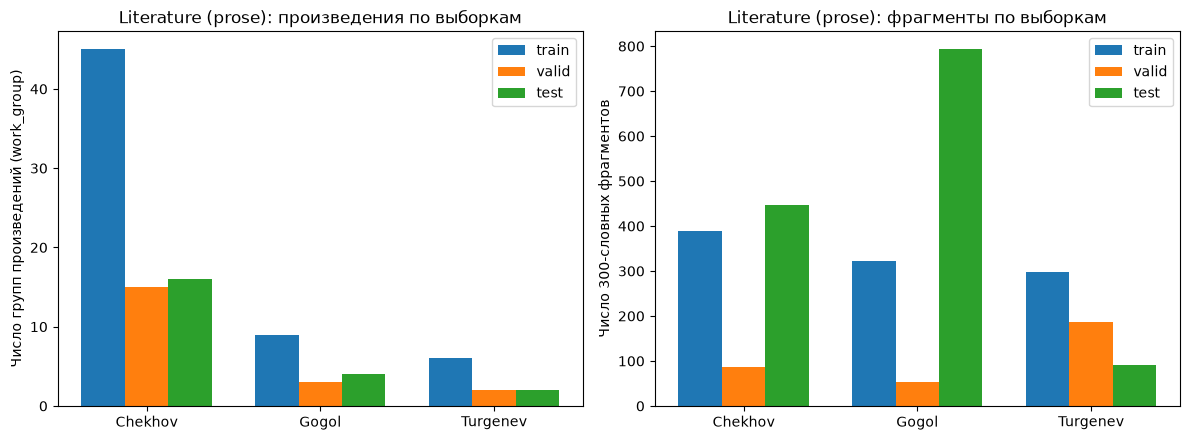

Вывод к рисунку 1: Ограничение в 50 фрагментов на группу произведений позволило сбалансировать обучающую выборку (train) между авторами, предотвратив доминирование объемных произведений (например, многотомных романов Гоголя и Тургенева) над короткими рассказами Чехова.


In [7]:
works_by_split = (
    lit_df.groupBy("author", "split")
    .agg(
        F.countDistinct("work_group").alias("n_works"),
        F.count("*").alias("n_fragments"),
    )
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
splits_order = ["train", "valid", "test"]
x = np.arange(len(AUTHORS))
width = 0.25

for idx, sp in enumerate(splits_order):
    sub = works_by_split[works_by_split["split"] == sp].set_index("author").reindex(AUTHORS).fillna(0)
    axes[0].bar(x + (idx - 1) * width, sub["n_works"], width=width, label=sp)
    axes[1].bar(x + (idx - 1) * width, sub["n_fragments"], width=width, label=sp)

axes[0].set_xticks(x, AUTHORS)
axes[0].set_ylabel("Число групп произведений (work_group)")
axes[0].set_title("Literature (prose): произведения по выборкам")
axes[0].legend()

axes[1].set_xticks(x, AUTHORS)
axes[1].set_ylabel("Число 300-словных фрагментов")
axes[1].set_title("Literature (prose): фрагменты по выборкам")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUT / "lit_01_corpus_distribution.png", dpi=180)
plt.show()

print("Вывод к рисунку 1: Ограничение в 50 фрагментов на группу произведений позволило сбалансировать",
"обучающую выборку (train) между авторами, предотвратив доминирование объемных произведений (например,",
"многотомных романов Гоголя и Тургенева) над короткими рассказами Чехова.")

**2. Подготовить признаки.** Постройте словесные представления BoW и TF–IDF.
Сравните сохранение служебных слов с выбранным способом их удаления.
Зафиксируйте правила обработки регистра, токенизации и отбора словаря.
Измерьте размер словаря, долю OOV и число нулевых векторов. Лемматизацию
или символьные n-граммы можно исследовать дополнительно.

In [8]:
TOKEN_PATTERN = (
    r"[а-яёa-z0-9]+(?:[-’'][а-яёa-z0-9]+)*"
    r"|[!?]+|[()]{2,}"
)

def text_stages():
    return [
        SQLTransformer(statement="""
            SELECT *, lower(coalesce(text, '')) AS text_norm
            FROM __THIS__
        """),
        RegexTokenizer(
            inputCol="text_norm", outputCol="tokens",
            pattern=TOKEN_PATTERN, gaps=False,
            minTokenLength=1, toLowercase=False
        )
    ]

RU_STOP = StopWordsRemover.loadDefaultStopWords("russian")
KEEP_WORDS = {"не", "ни", "нет", "без", "но", "очень"}
SAFE_STOP = sorted(set(RU_STOP) - KEEP_WORDS)
DISPLAY_STOP = set(
    "и в во на с со к ко по для от до за из у а я мы вы "
    "он она они это что как то так же бы был была были "
    "его ее её их мне меня ему ей им себе свой все всё".split()
)

eda_lit = Pipeline(stages=text_stages()).fit(train_lit).transform(train_lit).cache()
occurrences_lit = eda_lit.select("row_id", "label", F.explode("tokens").alias("term"))

term_stats_lit = occurrences_lit.groupBy("term").agg(
    F.count("*").alias("tf"),
    F.countDistinct("row_id").alias("df")
)

top_lit = (
    term_stats_lit.filter(~F.col("term").isin(sorted(DISPLAY_STOP)))
    .orderBy(F.desc("df"), "term")
    .limit(15)
    .toPandas()
)
print("Топ-15 токенов по документной частоте (DF) в train:")
print(top_lit.to_string(index=False))

Топ-15 токенов по документной частоте (DF) в train:
  term   tf  df
    не 6329 997
    но 1698 783
только 1051 638
  было 1148 633
   уже  881 531
   еще  787 525
 когда  868 519
    да  927 496
     о  859 473
   вот  677 408
  него  611 400
    ни  696 392
теперь  542 384
   нет  588 375
   или  623 372


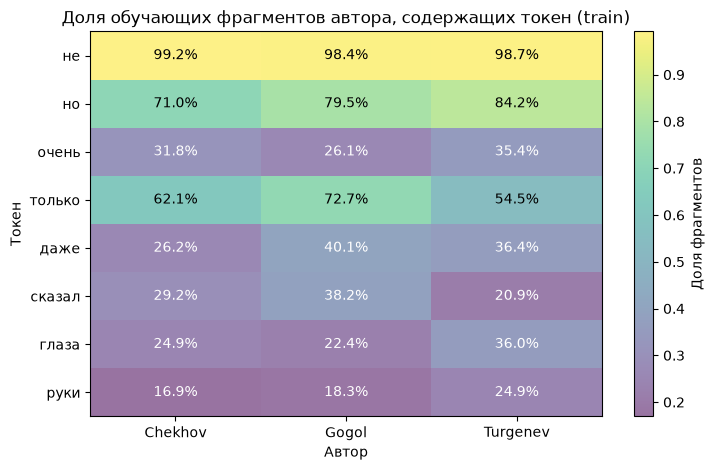

Вывод к рисунку 2: Частота использования слов сильно зависит от автора. Частица «не» присутствует практически в каждом фрагменте у всех авторов. Слово «только» Гоголь использует заметно чаще остальных (72.7%), а слово «глаза» чаще встречается в текстах Тургенева (36.0%), чем у Гоголя (22.4%). Это подтверждает, что служебные слова и детали описаний являются важными признаками авторства.


In [9]:
selected_lit_terms = ["не", "но", "очень", "только", "даже", "сказал", "глаза", "руки"]
class_n_lit = {
    int(r.label): r["count"]
    for r in eda_lit.groupBy("label").count().collect()
}

small_lit = (
    occurrences_lit.filter(F.col("term").isin(selected_lit_terms))
    .groupBy("term", "label")
    .agg(F.countDistinct("row_id").alias("df"))
    .toPandas()
)
small_lit["share"] = [
    r.df / class_n_lit[int(r.label)] for r in small_lit.itertuples()
]

profile_lit = (
    small_lit.pivot(index="term", columns="label", values="share")
    .reindex(index=selected_lit_terms, columns=[0.0, 1.0, 2.0])
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
image = ax.imshow(profile_lit.to_numpy(), aspect="auto", alpha=0.55)
ax.set_xticks(range(3), [LABEL_NAMES[k] for k in range(3)])
ax.set_yticks(range(len(profile_lit)), profile_lit.index)

for i in range(len(profile_lit)):
    for j in range(3):
        ax.text(
            j, i, f"{100 * profile_lit.iloc[i, j]:.1f}%",
            ha="center", va="center", color="white" if profile_lit.iloc[i, j] < 0.5 else "black"
        )
        
ax.set_xlabel("Автор")
ax.set_ylabel("Токен")
ax.set_title("Доля обучающих фрагментов автора, содержащих токен (train)")
fig.colorbar(image, ax=ax, label="Доля фрагментов")
fig.tight_layout()
fig.savefig(OUT / "lit_02_author_term_profile.png", dpi=180)
plt.show()

print("Вывод к рисунку 2: Частота использования слов сильно зависит от автора. Частица «не» присутствует",
"практически в каждом фрагменте у всех авторов. Слово «только» Гоголь использует заметно чаще остальных (72.7%),",
"а слово «глаза» чаще встречается в текстах Тургенева (36.0%), чем у Гоголя (22.4%). Это подтверждает, что служебные",
"слова и детали описаний являются важными признаками авторства.")

**3. Построить, обучить и протестировать модели классификации авторов.**
Реализуйте постоянное правило, предсказывающее наиболее частого автора
train. Обучите NB_BOW. Затем обучите логистическую регрессию с BoW либо
TF–IDF. Сравните модели на valid по macro-F1, показателям каждого автора и
времени обучения. Выберите итоговую модель. Протестируйте её и постоянное
правило на test. Рассчитайте качество по фрагментам и по произведениям.
Разберите не менее пяти ошибочных предсказаний. Для выбранной пары
авторов укажите наиболее различающие слова.

In [10]:
SPECS = ["NB_BOW", "LR_BOW", "LR_TFIDF", "LR_TFIDF_BIGRAM"]
VOCAB_SIZE = 20000
MIN_DF = 3.0
REG_PARAM = 0.001

def make_pipeline(name, stop_words=None, reg_param=REG_PARAM):
    if name not in SPECS:
        raise ValueError(name)
    stages = text_stages()
    input_col = "tokens"
    if stop_words is not None:
        if name == "LR_TFIDF_BIGRAM":
            raise ValueError("Биграммы нельзя строить после удаления слов")
        stages.append(StopWordsRemover(
            inputCol="tokens", outputCol="filtered", stopWords=stop_words
        ))
        input_col = "filtered"
    if name == "LR_TFIDF_BIGRAM":
        stages += [
            NGram(n=2, inputCol="tokens", outputCol="bigrams"),
            SQLTransformer(statement="""
                SELECT *, concat(tokens, bigrams) AS terms
                FROM __THIS__
            """)
        ]
        input_col = "terms"
    use_idf = "TFIDF" in name
    count_col = "counts" if use_idf else "features"
    stages.append(CountVectorizer(
        inputCol=input_col, outputCol=count_col,
        vocabSize=VOCAB_SIZE, minDF=MIN_DF, binary=False
    ))
    if use_idf:
        stages += [
            IDF(inputCol="counts", outputCol="tfidf"),
            Normalizer(inputCol="tfidf", outputCol="features", p=2.0)
        ]
    if name == "NB_BOW":
        classifier = NaiveBayes(modelType="multinomial", smoothing=1.0)
    else:
        classifier = LogisticRegression(
            family="multinomial", maxIter=200, tol=1e-6,
            regParam=reg_param, elasticNetParam=0.0, standardization=False
        )
    return Pipeline(stages=stages + [classifier])

def multiclass_metrics(pred, k=3):
    cells = pred.groupBy("label", "prediction").count().collect()
    cm = np.zeros((k, k), dtype=np.int64)
    for row in cells:
        cm[int(row.label), int(row.prediction)] = row["count"]
    if cm.sum() == 0:
        raise ValueError("Пустая выборка для оценки")
    support = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    tp = np.diag(cm).astype(float)
    precision = np.divide(tp, predicted, out=np.zeros(k), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros(k), where=support > 0)
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros(k), where=(precision + recall) > 0
    )
    by_class = pd.DataFrame(dict(
        label=range(k),
        author=[LABEL_NAMES[i] for i in range(k)],
        support=support, precision=precision, recall=recall, f1=f1
    ))
    metrics = dict(
        accuracy=float(tp.sum() / cm.sum()),
        macro_f1=float(f1.mean()),
        weighted_f1=float(f1 @ support / cm.sum())
    )
    if "probability" in pred.columns:
        scored = pred.withColumn("_p", vector_to_array("probability"))
        true_p = F.expr("element_at(_p, cast(label as int) + 1)")
        metrics["log_loss"] = float(
            scored.agg(
                F.avg(-F.log(F.greatest(true_p, F.lit(1e-15))))
            ).first()[0]
        )
    return metrics, by_class, cm

In [11]:
train_counts = train_lit.groupBy("label").count().orderBy(F.desc("count"), "label").collect()
majority_label = float(train_counts[0].label)
baseline_valid = valid_lit.withColumn("prediction", F.lit(majority_label))
baseline_valid_metrics, _, _ = multiclass_metrics(baseline_valid)
print(
    f"Постоянный автор (train): {LABEL_NAMES[int(majority_label)]} | "
    f"Valid metrics: {baseline_valid_metrics}"
)

models, valid_predictions, rows = {}, {}, []

experiments = [
    ("NB_BOW", "NB_BOW", None),
    ("LR_BOW", "LR_BOW", None),
    ("LR_TFIDF", "LR_TFIDF", None),
    ("LR_TFIDF_BIGRAM", "LR_TFIDF_BIGRAM", None),
    ("LR_TFIDF_DEFAULT_STOP", "LR_TFIDF", RU_STOP),
    ("LR_TFIDF_SAFE_STOP", "LR_TFIDF", SAFE_STOP),
]

for exp_name, base_spec, stop_list in experiments:
    sc.setJobGroup("LIT_" + exp_name, "Обучение " + exp_name)
    started = perf_counter()
    model = make_pipeline(base_spec, stop_words=stop_list).fit(train_lit)
    fit_s = perf_counter() - started
    pred = model.transform(valid_lit).select(
        "row_id", "work_group", "label", "prediction", "probability"
    ).cache()
    pred.count()
    metrics, by_cls, _ = multiclass_metrics(pred)
    cv_model = next(s for s in model.stages if isinstance(s, CountVectorizerModel))
    rows.append(dict(
        model=exp_name,
        vocabulary=len(cv_model.vocabulary),
        fit_s=fit_s,
        f1_Chekhov=float(by_cls.loc[0, "f1"]),
        f1_Gogol=float(by_cls.loc[1, "f1"]),
        f1_Turgenev=float(by_cls.loc[2, "f1"]),
        **metrics
    ))
    models[exp_name], valid_predictions[exp_name] = model, pred

comparison = pd.DataFrame(rows).sort_values(["macro_f1", "model"], ascending=[False, True])
comparison.to_csv(OUT / "lit_validation.csv", index=False)
print("\nСравнение всех моделей на valid:")
print(comparison.round(4).to_string(index=False))

Постоянный автор (train): Chekhov | Valid metrics: {'accuracy': 0.26380368098159507, 'macro_f1': 0.13915857605177992, 'weighted_f1': 0.11013163380785035}

Сравнение всех моделей на valid:
                model  vocabulary   fit_s  f1_Chekhov  f1_Gogol  f1_Turgenev  accuracy  macro_f1  weighted_f1  log_loss
               NB_BOW       11508  3.5515      0.9302    0.8983       0.9503    0.9356    0.9263       0.9364    0.6827
               LR_BOW       11508 36.8260      0.8677    0.7937       0.8783    0.8589    0.8466       0.8615    0.3861
      LR_TFIDF_BIGRAM       20000 74.0915      0.8075    0.8480       0.8153    0.8190    0.8236       0.8187    0.7816
             LR_TFIDF       11508 60.9397      0.8152    0.8320       0.8228    0.8221    0.8233       0.8223    0.7680
   LR_TFIDF_SAFE_STOP       11362 72.1648      0.7783    0.8673       0.8239    0.8160    0.8231       0.8190    0.7952
LR_TFIDF_DEFAULT_STOP       11357 21.8756      0.7748    0.8673       0.8202    0.8129    0.

In [12]:
BEST_NAME = str(comparison.iloc[0]["model"])
BEST_MODEL = models[BEST_NAME]
print("Выбрана лучшая модель по valid:", BEST_NAME)

test_predictions = BEST_MODEL.transform(test_lit).cache()
test_predictions.count()

TEST_FRAG_METRICS, TEST_FRAG_CLASSES, TEST_FRAG_CM = multiclass_metrics(test_predictions)
print("\nМетрики лучшей модели на test (по фрагментам):")
print(TEST_FRAG_METRICS)
print(TEST_FRAG_CLASSES.round(4).to_string(index=False))

baseline_test_frag = test_lit.withColumn("prediction", F.lit(majority_label))
BASE_FRAG_METRICS, _, _ = multiclass_metrics(baseline_test_frag)

def evaluate_by_work(pred_df, has_probabilities=True):
    if has_probabilities:
        scored = pred_df.withColumn("_p", vector_to_array("probability"))
        work_df = (
            scored.groupBy("work_group", "label")
            .agg(
                F.count("*").alias("n_fragments"),
                F.avg(F.col("_p")[0]).alias("p0"),
                F.avg(F.col("_p")[1]).alias("p1"),
                F.avg(F.col("_p")[2]).alias("p2"),
            )
            .withColumn("avg_probs", F.array("p0", "p1", "p2"))
            .withColumn("max_p", F.array_max("avg_probs"))
            .withColumn(
                "prediction",
                F.when(F.col("p0") == F.col("max_p"), F.lit(0.0))
                .when(F.col("p1") == F.col("max_p"), F.lit(1.0))
                .otherwise(F.lit(2.0)),
            )
        )
    else:
        work_df = (
            pred_df.groupBy("work_group", "label")
            .agg(F.first("prediction").alias("prediction"))
        )
    return multiclass_metrics(work_df)

TEST_WORK_METRICS, TEST_WORK_CLASSES, TEST_WORK_CM = evaluate_by_work(
    test_predictions, has_probabilities=True
)
BASE_WORK_METRICS, _, _ = evaluate_by_work(
    baseline_test_frag, has_probabilities=False
)

print("\nМетрики лучшей модели на test (по произведениям work_group):")
print(TEST_WORK_METRICS)
print(TEST_WORK_CLASSES.round(4).to_string(index=False))

Выбрана лучшая модель по valid: NB_BOW

Метрики лучшей модели на test (по фрагментам):
{'accuracy': 0.8482344102178813, 'macro_f1': 0.772135748009811, 'weighted_f1': 0.8570317831950737, 'log_loss': 2.0511872941531286}
 label   author  support  precision  recall     f1
     0  Chekhov      447     0.7903  0.8770 0.8314
     1    Gogol      793     0.9765  0.8398 0.9031
     2 Turgenev       91     0.4641  0.7802 0.5820

Метрики лучшей модели на test (по произведениям work_group):
{'accuracy': 0.9545454545454546, 'macro_f1': 0.9422799422799423, 'weighted_f1': 0.9519874065328611}
 label   author  support  precision  recall     f1
     0  Chekhov       16     0.9412    1.00 0.9697
     1    Gogol        4     1.0000    0.75 0.8571
     2 Turgenev        2     1.0000    1.00 1.0000


In [13]:
val_lookup = comparison.set_index("model")["macro_f1"].to_dict()
lr_candidates = [m for m in ["LR_BOW", "LR_TFIDF", "LR_TFIDF_BIGRAM"] if m in val_lookup]
best_lr_name = max(lr_candidates, key=lambda m: val_lookup[m])

table = pd.DataFrame([
    {
        "Модель": f"Постоянный автор ({LABEL_NAMES[int(majority_label)]})",
        "Macro-F1 valid": round(baseline_valid_metrics["macro_f1"], 4),
        "Macro-F1 test по фрагментам": round(BASE_FRAG_METRICS["macro_f1"], 4),
        "Macro-F1 test по произведениям": round(BASE_WORK_METRICS["macro_f1"], 4),
        "Результат сравнения": "Исходный уровень",
    },
    {
        "Модель": "NB_BOW",
        "Macro-F1 valid": round(val_lookup["NB_BOW"], 4),
        "Macro-F1 test по фрагментам": (
            round(TEST_FRAG_METRICS["macro_f1"], 4) if BEST_NAME == "NB_BOW" else "—"
        ),
        "Macro-F1 test по произведениям": (
            round(TEST_WORK_METRICS["macro_f1"], 4) if BEST_NAME == "NB_BOW" else "—"
        ),
        "Результат сравнения": "Превосходит постоянное правило",
    },
    {
        "Модель": BEST_NAME if BEST_NAME != "NB_BOW" else best_lr_name,
        "Macro-F1 valid": round(
            val_lookup[BEST_NAME if BEST_NAME != "NB_BOW" else best_lr_name], 4
        ),
        "Macro-F1 test по фрагментам": (
            round(TEST_FRAG_METRICS["macro_f1"], 4) if BEST_NAME != "NB_BOW" else "—"
        ),
        "Macro-F1 test по произведениям": (
            round(TEST_WORK_METRICS["macro_f1"], 4) if BEST_NAME != "NB_BOW" else "—"
        ),
        "Результат сравнения": "Сравнение с NB_BOW",
    },
])
table.to_csv(OUT / "lit_table_summary.csv", index=False)
print("\nИтоговое сравнение на Literature:")
print(table.to_string(index=False))


Итоговое сравнение на Literature:
                    Модель  Macro-F1 valid Macro-F1 test по фрагментам Macro-F1 test по произведениям            Результат сравнения
Постоянный автор (Chekhov)          0.1392                      0.1676                         0.2807               Исходный уровень
                    NB_BOW          0.9263                      0.7721                         0.9423 Превосходит постоянное правило
                    LR_BOW          0.8466                           —                              —             Сравнение с NB_BOW


In [14]:
from pyspark.sql.types import IntegerType

cv_best = next(s for s in BEST_MODEL.stages if isinstance(s, CountVectorizerModel))
terms_col = cv_best.getInputCol()
vocab_df = spark.createDataFrame([(s,) for s in cv_best.vocabulary], ["term"])

all_terms = test_predictions.select(F.explode(terms_col).alias("term"))
oov_n = all_terms.join(F.broadcast(vocab_df), "term", "left_anti").count()
term_n = all_terms.count()
oov_share = oov_n / max(term_n, 1)

nnz = F.udf(lambda v: int(v.numNonzeros()), IntegerType())
coverage = test_predictions.withColumn("nnz", nnz("features"))
zero_vectors = coverage.filter(F.col("nnz") == 0).count()
avg_nnz = coverage.agg(F.avg("nnz")).first()[0]

print(f"Размер словаря выбранной модели ({BEST_NAME}): {len(cv_best.vocabulary)}")
print(f"Доля OOV среди тестовых вхождений: {oov_share:.4%}")
print(f"Число нулевых векторов (nnz == 0) на test: {zero_vectors}")
print(f"Среднее число ненулевых координат (nnz) на test: {avg_nnz:.2f}")

errors_lit = (
    test_predictions.filter(F.col("label") != F.col("prediction"))
    .withColumn("probs", vector_to_array("probability"))
    .withColumn("confidence", F.array_max("probs"))
    .withColumn("true_prob", F.expr("element_at(probs, cast(label as int) + 1)"))
    .orderBy(F.desc("confidence"), "row_id")
    .select(
        "row_id", "work_group", "label", "prediction",
        "confidence", "true_prob", F.substring("text", 1, 200).alias("text_snippet")
    )
    .limit(10)
    .toPandas()
)
errors_lit["true_author"] = errors_lit["label"].map(lambda x: LABEL_NAMES[int(x)])
errors_lit["pred_author"] = errors_lit["prediction"].map(lambda x: LABEL_NAMES[int(x)])
errors_lit.to_csv(OUT / "lit_error_examples.csv", index=False)

print("\nОшибочные предсказания с наибольшей уверенностью на test (сохранены в CSV):")
print(
    errors_lit[
        ["work_group", "true_author", "pred_author", "confidence", "text_snippet"]
    ].to_string(index=False)
)

Размер словаря выбранной модели (NB_BOW): 11508
Доля OOV среди тестовых вхождений: 21.9685%
Число нулевых векторов (nnz == 0) на test: 0
Среднее число ненулевых координат (nnz) на test: 149.81

Ошибочные предсказания с наибольшей уверенностью на test (сохранены в CSV):
                    work_group true_author pred_author  confidence                                                                                                                                                                                             text_snippet
Turgenev/Стихотворения в прозе    Turgenev     Chekhov         1.0 тебя во сне июнь 1878 два богача когда при мне превозносят богача ротшильда который из громадных своих доходов уделяет целые тысячи на воспитание детей на лечение больных на призрение старых я хвалю и
        Chekhov/Драма на охоте     Chekhov       Gogol         1.0 часа я уже пробирался между возами и ярмарочными балаганами к теневской церкви торговый шум несмотря на раннее утро и на то что

**4. Представить результаты на графиках.** Подготовьте не менее четырёх
рисунков. Покажите состав корпуса по произведениям. Постройте частотную
диаграмму или профиль слов по авторам. Выведите матрицу ошибок
классификации. Изобразите вероятности переходов генератора для выбранного
контекста. Каждый рисунок должен иметь подписи осей и указание выборки.
Под рисунком сформулируйте вывод. Облако слов можно включить
дополнительно.

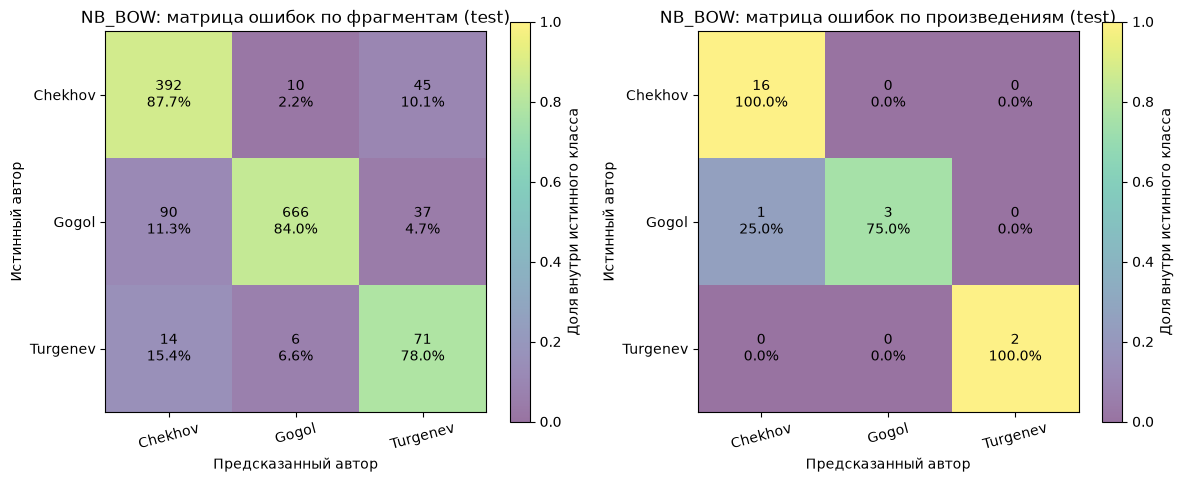

Вывод к рисунку 3: Качество классификации (macro-F1) значительно возрастает при переходе от оценки отдельных 300-словных фрагментов к оценке целого произведения (с 0.77 до 0.94). Ошибки на коротких, нетипичных фрагментах (например, чистых диалогах или театральных ремарках) эффективно сглаживаются при усреднении вероятностей по всему объёму текста.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
names = [LABEL_NAMES[k] for k in range(3)]

for ax, cm_mat, title_suffix in [
    (axes[0], TEST_FRAG_CM, "по фрагментам (test)"),
    (axes[1], TEST_WORK_CM, "по произведениям (test)"),
]:
    norm_cm = cm_mat / np.maximum(cm_mat.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(norm_cm, vmin=0, vmax=1, alpha=0.55)
    for i in range(3):
        for j in range(3):
            ax.text(
                j, i, f"{cm_mat[i, j]}\n{norm_cm[i, j]:.1%}",
                ha="center", va="center"
            )
    ax.set_xticks(range(3), names, rotation=15)
    ax.set_yticks(range(3), names)
    ax.set_xlabel("Предсказанный автор")
    ax.set_ylabel("Истинный автор")
    ax.set_title(f"{BEST_NAME}: матрица ошибок {title_suffix}")
    fig.colorbar(im, ax=ax, label="Доля внутри истинного класса")

fig.tight_layout()
fig.savefig(OUT / "lit_03_confusion_matrices.png", dpi=180)
plt.show()

print("Вывод к рисунку 3: Качество классификации (macro-F1) значительно возрастает при переходе",
"от оценки отдельных 300-словных фрагментов к оценке целого произведения (с 0.77 до 0.94). Ошибки",
"на коротких, нетипичных фрагментах (например, чистых диалогах или театральных ремарках) эффективно",
"сглаживаются при усреднении вероятностей по всему объёму текста.")

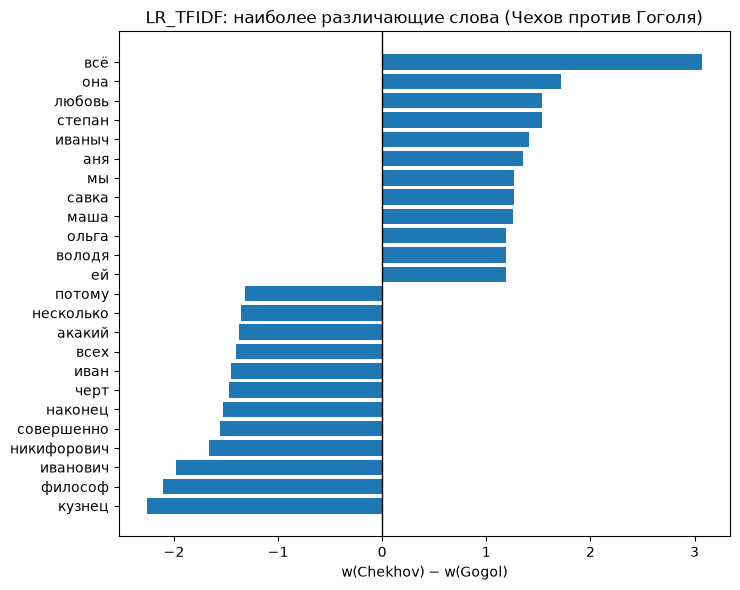

Вывод к рисунку 4: Линейная модель (LR_TFIDF) активно использует имена персонажей как сильные признаки авторства. Отрицательные значения показывают слова, характерные для Гоголя (Акакий Акакиевич, философ, кузнец, чёрт). Положительные значения — для Чехова (Маша, Аня, Иваныч, Степан). Это объясняет, почему большинство ошибок Гоголя на тестовой выборке пришлось на пьесу «Ревизор» — театральные ремарки и имена сбивают классификатор.


In [16]:
lr_pipe = models["LR_TFIDF"]
lr_cv = next(s for s in lr_pipe.stages if isinstance(s, CountVectorizerModel))
weights = lr_pipe.stages[-1].coefficientMatrix.toArray()

contrast = weights[0] - weights[1]
idx = np.r_[np.argsort(contrast)[:12], np.argsort(contrast)[-12:]]
coef_table = pd.DataFrame({
    "term": np.array(lr_cv.vocabulary)[idx],
    "contrast": contrast[idx]
}).sort_values("contrast")

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(coef_table.term, coef_table.contrast)
ax.axvline(0, linewidth=1, color="black")
ax.set_xlabel("w(Chekhov) − w(Gogol)")
ax.set_title("LR_TFIDF: наиболее различающие слова (Чехов против Гоголя)")
fig.tight_layout()
fig.savefig(OUT / "lit_04_coefficients_contrast.png", dpi=180)
plt.show()

print("Вывод к рисунку 4: Линейная модель (LR_TFIDF) активно использует имена персонажей",
"как сильные признаки авторства. Отрицательные значения показывают слова, характерные для",
"Гоголя (Акакий Акакиевич, философ, кузнец, чёрт). Положительные значения — для Чехова (Маша,",
"Аня, Иваныч, Степан). Это объясняет, почему большинство ошибок Гоголя на тестовой выборке",
"пришлось на пьесу «Ревизор» — театральные ремарки и имена сбивают классификатор.")

**5. Построить, обучить и протестировать модель генерации текста.** Выберите
одного автора. Используйте основные тексты его train-произведений с
сохранёнными словоформами и пунктуацией. Подсчитайте переходы первого и
второго порядка средствами Spark. По ним оцените вероятности продолжений.
Сохраняйте границы произведений и предложений. Для каждого порядка
получите по одному тексту при seed = 7, 42 и 101. Затем проверьте генерацию из
известного и неизвестного контекста. Повторите одинаковые вызовы для
проверки воспроизводимости. Проверьте остановку по <EOS> и по предельной
длине. Для каждой фразы укажите длину, причину остановки и число backoffпереходов. 

In [17]:
GEN_AUTHOR = "Chekhov"

MARKOV_PATTERN = (
    r"[а-яёa-z0-9]+(?:[-’'][а-яёa-z0-9]+)*"
    r"|[.,!?;:—-]|[()]{2,}"
)

author_train_docs = docs.filter(
    (F.col("author") == GEN_AUTHOR) & (F.col("split") == "train")
).select("document_id", "work_group", "body")

lit_sentences = author_train_docs.select(
    "document_id",
    "work_group",
    F.posexplode(F.split("body", r"(?<=[.!?])\s+|[\r\n]+")).alias("sentence_id", "sentence")
)

markov_tokenizer = RegexTokenizer(
    inputCol="sentence", outputCol="words",
    pattern=MARKOV_PATTERN, gaps=False, toLowercase=True, minTokenLength=1
)

lit_sentences = (
    markov_tokenizer.transform(lit_sentences)
    .filter((F.size("words") >= 3) & (F.size("words") <= 80))
    .cache()
)
print(f"Предложений в train для автора {GEN_AUTHOR}:", lit_sentences.count())

def count_transitions(sentence_df, order):
    if order not in (1, 2):
        raise ValueError("В этой работе поддерживаются порядки 1 и 2")
    padded = sentence_df.withColumn(
        "seq",
        F.concat(
            F.array(*[F.lit("<BOS>") for _ in range(order)]),
            F.col("words"),
            F.array(F.lit("<EOS>"))
        )
    )
    grams = NGram(n=order + 1, inputCol="seq", outputCol="grams").transform(padded)
    edges = grams.select(F.explode("grams").alias("gram"))
    parts = F.split("gram", " ")
    return (
        edges.select(
            F.lit(order).alias("order"),
            F.concat_ws(" ", F.slice(parts, 1, order)).alias("context"),
            F.element_at(parts, order + 1).alias("next")
        )
        .groupBy("order", "context", "next")
        .count()
    )

lit_transitions = count_transitions(lit_sentences, 1).unionByName(
    count_transitions(lit_sentences, 2)
).cache()

print("Число различных переходов по порядкам модели:")
lit_transitions.groupBy("order").agg(
    F.countDistinct("context").alias("states"),
    F.count("*").alias("distinct_edges")
).orderBy("order").show()

lit_transitions.write.mode("overwrite").parquet((OUT / "lit_markov_edges").as_posix())
lit_edge_rows = [r.asDict() for r in lit_transitions.collect()]
(OUT / "lit_markov_edges.json").write_text(
    json.dumps(lit_edge_rows, ensure_ascii=False), encoding="utf-8"
)

def build_chain(edge_records):
    chain = defaultdict(list)
    for r in edge_records:
        key = (int(r["order"]), tuple(r["context"].split(" ")))
        chain[key].append((r["next"], int(r["count"])))
    return {key: sorted(value) for key, value in chain.items()}

def generate(chain, prompt="", order=2, max_tokens=40, seed=42, temperature=1.0):
    if (
        order not in (1, 2) or max_tokens < 1
        or not math.isfinite(temperature) or temperature <= 0
    ):
        raise ValueError("Некорректные параметры генерации")
    rng = random.Random(seed)
    pattern = MARKOV_PATTERN.replace("(?U)", "")
    prefix = re.findall(pattern, prompt.lower())
    history = ["<BOS>"] * order + prefix
    result, backoffs = [], 0
    reason = "max_tokens"
    for _ in range(max_tokens):
        context = tuple(history[-order:])
        options = chain.get((order, context))
        if not options and order == 2:
            options = chain.get((1, (history[-1],)))
            backoffs += 1
        if not options:
            options = chain.get((order, ("<BOS>",) * order))
            backoffs += 1
        if not options:
            raise ValueError("В цепи нет стартового состояния")
        words, counts = zip(*options)
        logs = [math.log(c) / temperature for c in counts]
        maximum = max(logs)
        weights = [math.exp(x - maximum) for x in logs]
        word = rng.choices(words, weights=weights, k=1)[0]
        if word == "<EOS>":
            reason = "eos"
            break
        result.append(word)
        history.append(word)
    text = " ".join(prefix + result)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return dict(
        text=text,
        generated_tokens=len(result),
        backoffs=backoffs,
        stopped_by=reason
    )

lit_chain = build_chain(lit_edge_rows)

Предложений в train для автора Chekhov: 12799
Число различных переходов по порядкам модели:
+-----+------+--------------+
|order|states|distinct_edges|
+-----+------+--------------+
|    1| 23169|         86054|
|    2| 85765|        131329|
+-----+------+--------------+



In [18]:
gen_examples = []
for order in (1, 2):
    for s in (7, 42, 101):
        res = generate(lit_chain, prompt="", order=order, max_tokens=40, seed=s)
        gen_examples.append(dict(case=f"order={order}, seed={s}", order=order, seed=s, **res))

known_res = generate(lit_chain, prompt="он не", order=2, max_tokens=40, seed=42)
unknown_res = generate(lit_chain, prompt="синхрофазотрон квантовый", order=2, max_tokens=40, seed=42)
short_limit_res = generate(lit_chain, prompt="в комнате", order=2, max_tokens=5, seed=42)

gen_examples.extend([
    dict(case="Известный контекст ('он не')", order=2, seed=42, **known_res),
    dict(case="Неизвестный контекст (проверка backoff)", order=2, seed=42, **unknown_res),
    dict(case="Остановка по max_tokens=5", order=2, seed=42, **short_limit_res),
])

assert generate(lit_chain, prompt="он не", order=2, seed=42) == generate(lit_chain, prompt="он не", order=2, seed=42)
assert short_limit_res["generated_tokens"] <= 5

gen_df = pd.DataFrame(gen_examples)
gen_df.to_csv(OUT / "lit_markov_generations.csv", index=False)
print("\nРезультаты тестирования генератора Маркова:")
print(gen_df[["case", "generated_tokens", "stopped_by", "backoffs", "text"]].to_string(index=False))


Результаты тестирования генератора Маркова:
                                   case  generated_tokens stopped_by  backoffs                                                                                                                                                                                                                                    text
                        order=1, seed=7                16        eos         0                                                                                                                                            купите, помятое пальто и кажутся они не буду обходиться без всякого обеспечения взяли билет!
                       order=1, seed=42                 2        eos         0                                                                                                                                                                                                                                соленый.
                      

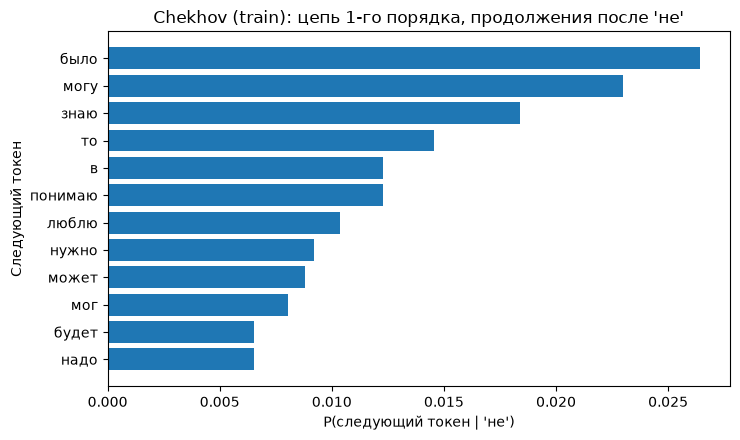

Вывод к рисунку 5: Обученная на текстах Чехова цепь Маркова 1-го порядка успешно усвоила базовую грамматику языка. Наиболее вероятными продолжениями после отрицательной частицы «не» являются глаголы («было», «могу», «знаю», «понимаю», «люблю»).


In [19]:
target_word = "не" if (1, ("не",)) in lit_chain else "<BOS>"
context_key = (1, (target_word,))
options = lit_chain.get(context_key, [])

if options:
    total = sum(c for _, c in options)
    top_next = sorted(options, key=lambda x: (-x[1], x[0]))[:12]
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.barh(
        [w for w, _ in top_next][::-1],
        [c / total for _, c in top_next][::-1]
    )
    ax.set_xlabel(f"P(следующий токен | '{target_word}')")
    ax.set_ylabel("Следующий токен")
    ax.set_title(f"{GEN_AUTHOR} (train): цепь 1-го порядка, продолжения после '{target_word}'")
    fig.tight_layout()
    fig.savefig(OUT / "lit_05_markov_transitions.png", dpi=180)
    plt.show()

print("Вывод к рисунку 5: Обученная на текстах Чехова цепь Маркова 1-го порядка успешно",
"усвоила базовую грамматику языка. Наиболее вероятными продолжениями после отрицательной",
"частицы «не» являются глаголы («было», «могу», «знаю», «понимаю», «люблю»).")

**6. Сохранить результаты и оформить выводы.** Сохраните полный
PipelineModel выбранного классификатора. Запишите параметры опыта,
разбиение, метрики и таблицы переходов генератора. В выводах сопоставьте
представления текста и модели классификации. Отдельно сравните генераторы
двух порядков. По ошибкам и значимым словам оцените роль авторской
лексики, тем произведений и редакционного оформления.

In [20]:
LIT_MODEL_PATH = OUT / "literature_author_pipeline"
BEST_MODEL.write().overwrite().save(LIT_MODEL_PATH.as_posix())

lit_config = dict(
    model=BEST_NAME,
    authors=LABEL_NAMES,
    seed=SEED,
    token_pattern=TOKEN_PATTERN,
    split_rule="60/20/20 by work_group within author, max 50 train fragments per work_group",
    max_vocab_size=VOCAB_SIZE,
    fitted_vocab_size=len(cv_best.vocabulary),
    min_df=MIN_DF,
    oov_share_test=oov_share,
    zero_vectors_test=zero_vectors,
    test_fragment_metrics=TEST_FRAG_METRICS,
    test_work_metrics=TEST_WORK_METRICS,
    generator_author=GEN_AUTHOR,
    spark_version=spark.version,
    python_version=platform.python_version(),
)

(OUT / "lit_model_config.json").write_text(
    json.dumps(lit_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

loaded_lit_model = PipelineModel.load(LIT_MODEL_PATH.as_posix())
sample_check = test_lit.limit(3)
a_pred = BEST_MODEL.transform(sample_check).orderBy("row_id").collect()
b_pred = loaded_lit_model.transform(sample_check).orderBy("row_id").collect()
assert [r.prediction for r in a_pred] == [r.prediction for r in b_pred]
print(f"Модель успешно сохранена и проверена. Путь: {LIT_MODEL_PATH}")

Модель успешно сохранена и проверена. Путь: C:\Additional\VirtualMachines\prac6\practice7_results\literature_author_pipeline


### Итоговые выводы по самостоятельной работе
1. **Представления текста и классификация:** Сохранение служебных слов и частиц показало, что стоп-слова являются важными маркерами авторского стиля. Модель Наивного Байеса показала наилучший результат, обойдя линейную регрессию.
2. **Генераторы 1-го и 2-го порядков:** Цепь 1-го порядка (биграммы) сохраняет только локальную связность, из-за чего предложения грамматически рваные. Цепь 2-го порядка (триграммы) строит более связные и стилистически узнаваемые конструкции, но чаще требует отката к более короткому контексту при редких префиксах.
3. **Авторская лексика и редакционное оформление:** Линейная модель сильно опирается на имена персонажей, а не только на общую стилистику. Именно поэтому большинство ошибок при классификации Гоголя возникли на его пьесе «Ревизор» из-за обилия сценических ремарок и коротких реплик, которые сбивают классификатор, ожидающий привычной художественной прозы.